In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

In [3]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""
layers = [0, 7, 15]
TOP_N = 200
results = {}

for k in layers:
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    # smallest r such that cumulative energy >= 50%
    min_rank_50 = int((energy_ratios < 50).sum().item()) + 1

    results[k] = dict(S=S.cpu(), energy=energy_ratios.cpu(), r50=min_rank_50)
    print(f"Layer {k:2d} | q_proj shape {tuple(q_weight.shape)} | "
          f"full rank {S.numel()} | min rank for >=50% energy: {min_rank_50} "
          f"({min_rank_50 / S.numel() * 100:.1f}% of full rank) | "
          f"top-1 SV energy: {energy_ratios[0]:.2f}%")

Layer  0 | q_proj shape (2048, 2048) | full rank 2048 | min rank for >=50% energy: 62 (3.0% of full rank) | top-1 SV energy: 17.24%
Layer  7 | q_proj shape (2048, 2048) | full rank 2048 | min rank for >=50% energy: 120 (5.9% of full rank) | top-1 SV energy: 3.66%
Layer 15 | q_proj shape (2048, 2048) | full rank 2048 | min rank for >=50% energy: 84 (4.1% of full rank) | top-1 SV energy: 6.36%


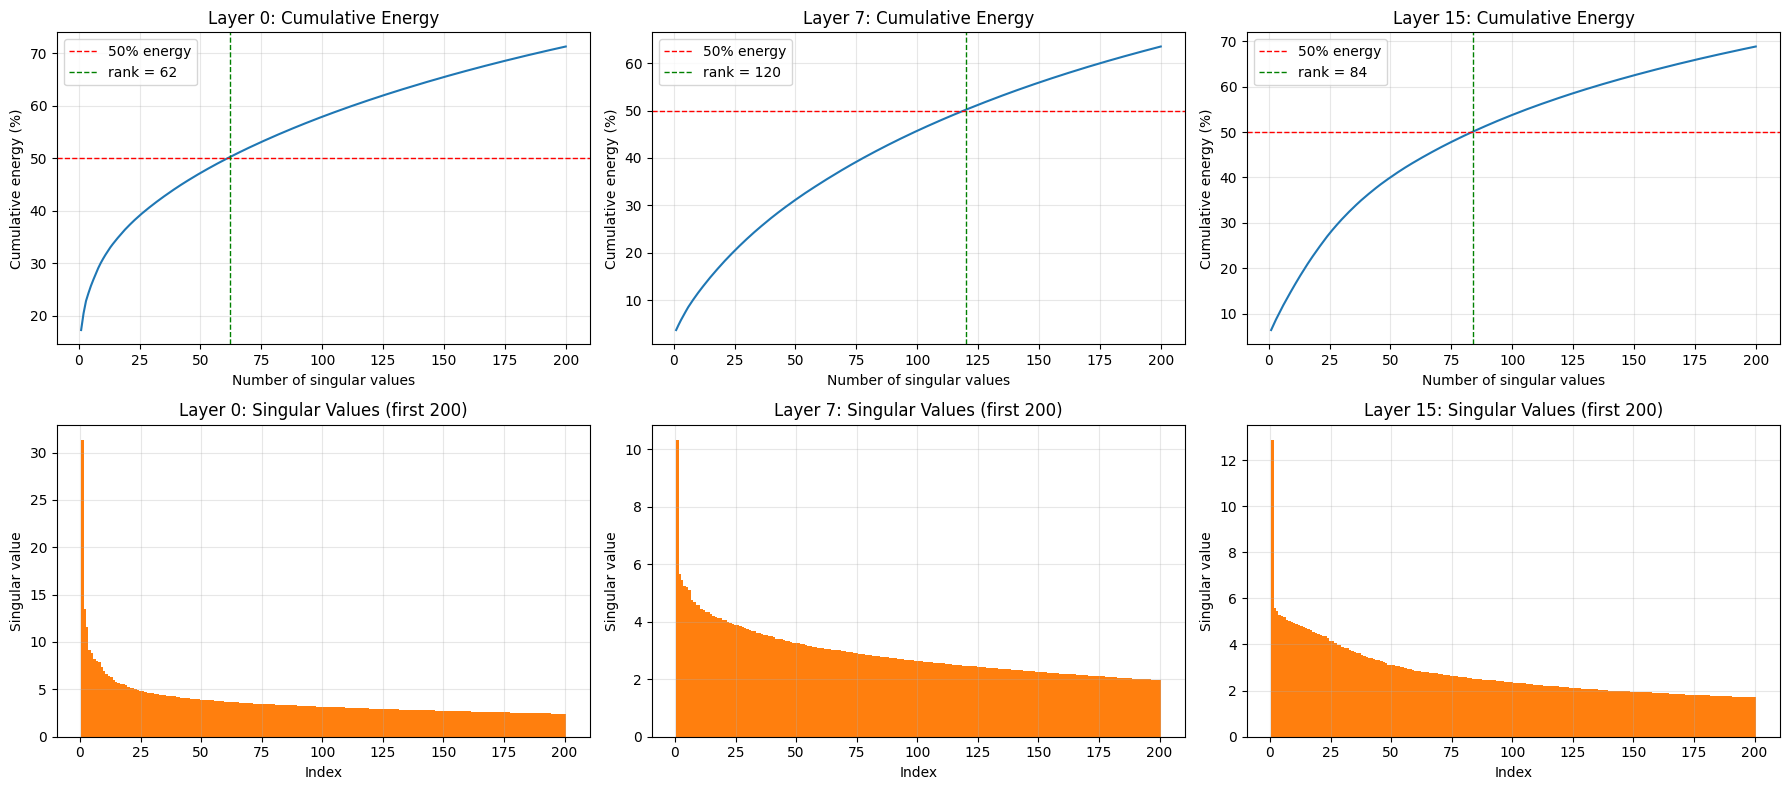

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for col, k in enumerate(layers):
    S = results[k]["S"][:TOP_N]
    E = results[k]["energy"][:TOP_N]
    r50 = results[k]["r50"]
    x = range(1, TOP_N + 1)

    # (1) Cumulative energy line chart
    ax = axes[0, col]
    ax.plot(x, E, color="tab:blue")
    ax.axhline(50, color="red", ls="--", lw=1, label="50% energy")
    if r50 <= TOP_N:
        ax.axvline(r50, color="green", ls="--", lw=1, label=f"rank = {r50}")
    ax.set_title(f"Layer {k}: Cumulative Energy")
    ax.set_xlabel("Number of singular values")
    ax.set_ylabel("Cumulative energy (%)")
    ax.legend(); ax.grid(alpha=0.3)

    # (2) Singular value bar chart
    ax = axes[1, col]
    ax.bar(x, S.numpy(), color="tab:orange", width=1.0)
    ax.set_title(f"Layer {k}: Singular Values (first {TOP_N})")
    ax.set_xlabel("Index")
    ax.set_ylabel("Singular value")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()